
## Brownian Motion & Geometric Brownian Motion

This notebook introduces Brownian motion through discrete random walks, derives geometric Brownian motion using Itô's lemma, and validates simulated asset-price paths against theoretical results.

### Brownian Motion

Standard Brownian motion $(W_t)_{t\in[0,T]}$ is a stochastic process satisfying:

- $W_0=0$.
- $W_t-W_s\sim\mathcal{N}(0,t-s)$ for $0\leq s<t\leq T$.
- Increments over disjoint intervals are independent.
- Sample paths are continuous almost surely.

Consequently, $W_t\sim\mathcal{N}(0,t)$.



### Simple Symmetric Random Walk

A simple symmetric random walk consists of independent steps $X_i\in\{-1,1\}$, with

$$
P(X_i=1)=P(X_i=-1)=\frac12.
$$

Starting from $S_0=0$, the position after $n$ steps is

$$
S_n=\sum_{i=1}^{n}X_i.
$$

Consequently, $\mathbb{E}[S_n]=0$ and $\operatorname{Var}(S_n)=n$.


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

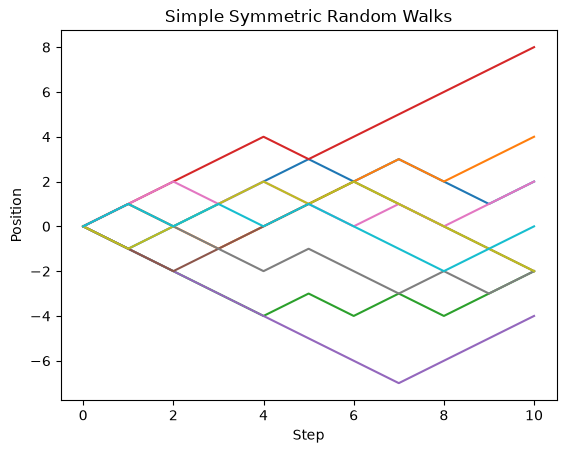

In [18]:
M = 10
n = 10
steps_array = np.arange(n + 1)

for _ in range(M):
    steps = np.random.choice([-1, 1], size=n)
    path = np.concatenate(([0], np.cumsum(steps)))

    plt.plot(steps_array, path)

plt.xlabel("Step")
plt.ylabel("Position")
plt.title("Simple Symmetric Random Walks")
plt.show()

### Scaled Symmetric Random Walk

To approximate Brownian motion over $[0,T]$, divide time into $n$ intervals of length $\Delta t=T/n$.

Each step is scaled by $\sqrt{\Delta t}$, giving

$$
\Delta X_i=\pm\sqrt{\Delta t}
$$

with equal probability. The position after $k$ steps is

$$
X_k=\sqrt{\Delta t}\sum_{i=1}^{k}\xi_i,
\qquad \xi_i\in\{-1,1\}.
$$

Consequently, $\mathbb{E}[X_k]=0$ and $\operatorname{Var}(X_k)=k\Delta t$.

As $n\to\infty$, the appropriately interpolated scaled random walk converges in distribution to Brownian motion.


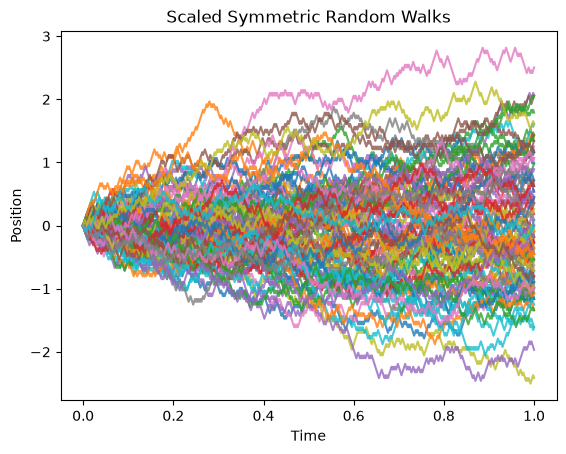

In [19]:
M = 100
T = 1
n = 500

t_array = np.linspace(0, T, n + 1)
delta_t = T / n

for _ in range(M):
    steps = np.random.choice([-1, 1], size=n)
    scaled_steps = np.sqrt(delta_t) * steps
    
    path = np.concatenate(([0], np.cumsum(scaled_steps)))

    plt.plot(t_array, path, alpha = 0.8)

plt.xlabel("Time")
plt.ylabel("Position")
plt.title("Scaled Symmetric Random Walks")
plt.show()


### Discrete Simulation of Brownian Motion

Brownian motion has independent Gaussian increments satisfying

$$
\Delta W_i=W_{t_i}-W_{t_{i-1}}\sim\mathcal{N}(0,\Delta t),
\qquad \Delta t=\frac{T}{n}.
$$

A Brownian path can therefore be simulated by generating independent increments and cumulatively summing them from $W_0=0$:

$$
W_{t_k}=\sum_{i=1}^{k}\Delta W_i.
$$

Unlike the scaled random walk, this produces the exact Brownian motion distribution at the discrete observation times.


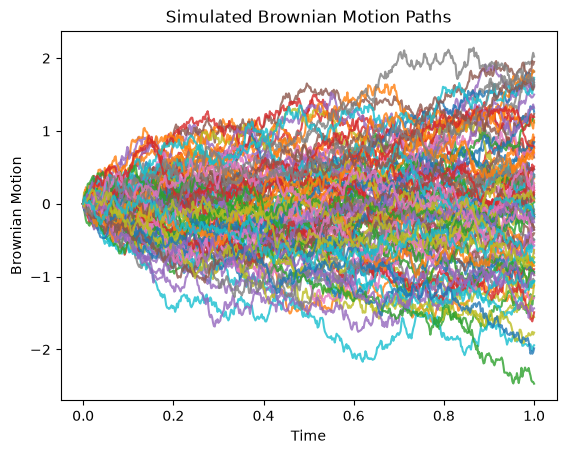

In [20]:
M = 100
T = 1
n = 500

t_array = np.linspace(0, T, n + 1)
delta_t = T / n

for _ in range(M):
    increments = np.random.normal(0, np.sqrt(delta_t), size=n)
    path = np.concatenate(([0], np.cumsum(increments)))

    plt.plot(t_array, path, alpha = 0.8)

plt.xlabel("Time")
plt.ylabel("Brownian Motion")
plt.title("Simulated Brownian Motion Paths")
plt.show()


### Drifted Brownian Motion

Drifted Brownian motion extends standard Brownian motion by introducing a deterministic drift $\mu$ and volatility $\sigma$:

$$
X_t=\mu t+\sigma W_t.
$$

Over a time interval $\Delta t$, the increments satisfy

$$
\Delta X_i\sim\mathcal{N}(\mu\Delta t,\sigma^2\Delta t).
$$

Consequently,

$$
\mathbb{E}[X_t]=\mu t,\qquad
\operatorname{Var}(X_t)=\sigma^2t.
$$

The drift determines the expected direction of the process, while volatility controls its dispersion.


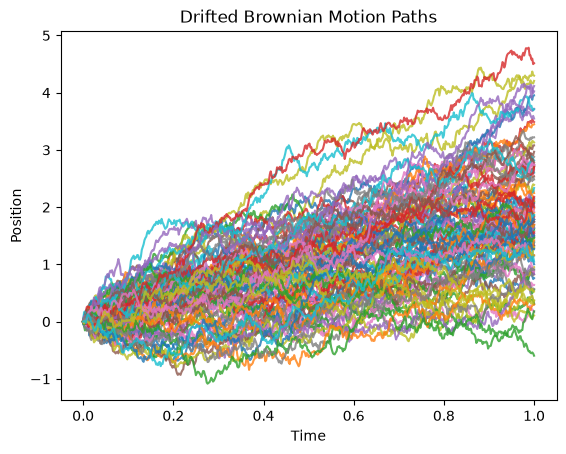

In [21]:
mu = 2
sigma = 1

M = 100
T = 1
n = 500

t_array = np.linspace(0, T, n + 1)
delta_t = T / n

for _ in range(M):
    increments = np.random.normal(mu * delta_t, sigma * np.sqrt(delta_t), n)
    path = np.concatenate(([0], np.cumsum(increments)))

    plt.plot(t_array, path, alpha = 0.8)

plt.xlabel("Time")
plt.ylabel("Position")
plt.title("Drifted Brownian Motion Paths")
plt.show()

### Itô's Lemma

For ordinary differentiable processes, increments over small intervals are of order $dt$, so terms such as $(dt)^2$ vanish in the Taylor expansion.
Brownian motion behaves differently; its increments scale as

$$
dW_t \sim \sqrt{dt}
\quad \Longrightarrow \quad
(dW_t)^2 \sim dt.
$$

So the second-order term involving Brownian motion, $(dW_t)^2$, can't be ignored.

In differential notation, this gives the standard Itô multiplication rules:

$$
(dW_t)^2 = dt, \qquad dW_t\,dt = 0, \qquad (dt)^2 = 0.
$$

For a function $f(t,X_t)$, once differentiable in time, twice differentiable in $X_t$, a second-order Taylor expansion together with the Itô rules gives

$$
\begin{aligned}
f(t+\Delta t,x+\Delta x)
\approx\;&
f(t,x)
+
\frac{\partial f}{\partial t}\Delta t
+
\frac{\partial f}{\partial x}\Delta x \\
&+
\frac{1}{2}
\left[
\frac{\partial^2 f}{\partial t^2}(\Delta t)^2
+
2\frac{\partial^2 f}{\partial t\,\partial x}\Delta t\,\Delta x
+
\frac{\partial^2 f}{\partial x^2}(\Delta x)^2
\right].
\end{aligned}
$$

The relevant terms reduce to
$$
df
=
\frac{\partial f}{\partial t}\,dt
+
\frac{\partial f}{\partial x}\,dX_t
+
\frac{1}{2}
\frac{\partial^2 f}{\partial x^2}(dX_t)^2.
$$

Now consider a general Itô process, 

$$dX_t = a(t,X_t)\,dt + b(t,X_t)\,dW_t$$

Using the Itô multiplication rules,

$$
(dX_t)^2
=
b^2(t,X_t)\,dt.
$$

Substituting and collecting the $dt$ and $dW_t$ terms gives

$$
df(t,X_t)
=
\left[
\frac{\partial f}{\partial t}
+
a(t,X_t)\frac{\partial f}{\partial x}
+
\frac{1}{2}b^2(t,X_t)\frac{\partial^2 f}{\partial x^2}
\right]dt
+
b(t,X_t)\frac{\partial f}{\partial x}\,dW_t.
$$

This is Itô's lemma for a general Itô process. The additional term

$$
\frac{1}{2}
b^2(t,X_t)
\frac{\partial^2 f}{\partial x^2}
\,dt
$$

Arises from the quadratic variation of Brownian motion. It captures the interaction between volatility of $X_t$ and curvature of $f$. This is used to transform geometric Brownian motion. Later, this result becomes key to deriving the Black-Scholes equation.





### Geometric Brownian Motion

Let $\{P_t\}_{t \geq 0}$ denote a stochastic process representing the price of an asset. Assume that $P_t$ is an Itô process of the form

$$
dP_t = a(t,P_t)\,dt + b(t,P_t)\,dB_t.
$$

Geometric Brownian motion is obtained by choosing the drift and diffusion coefficients to be proportional to the current asset price:

$$
a(t,P_t)=\mu P_t,
\qquad
b(t,P_t)=\sigma P_t.
$$

Where $\mu$ is the drift rate and $\sigma$ is the volatility. 

Hence,

$$
dP_t = \mu P_t\,dt + \sigma P_t\,dB_t.
$$
Since both terms are multiplied by $P_t$, the magnitude of both the expected price and random price changes scales with the current asset price.
To obtain the dynamics of the log price, define:

$$
f(P_t)=\ln P_t.
$$

Since $f$ has no explicit dependence on time, we obtain:

$$
\frac{\partial f}{\partial t}=0,
\qquad
\frac{\partial f}{\partial P}
=
\frac{1}{P_t},
\qquad
\frac{\partial^2 f}{\partial P^2}
=
-\frac{1}{P_t^2}.
$$

Applying Itô's lemma,

$$
df
=
\left[
a(t,P_t)\frac{\partial f}{\partial P}
+
\frac{1}{2}b^2(t,P_t)\frac{\partial^2 f}{\partial P^2}
\right]dt
+
b(t,P_t)\frac{\partial f}{\partial P}\,dB_t.
$$

Substituting $a(t,P_t)=\mu P_t, b(t,P_t)=\sigma P_t$ gives:

$$
d\ln P_t
=
\left[
\mu P_t\left(\frac{1}{P_t}\right)
+
\frac{1}{2}\sigma^2P_t^2
\left(-\frac{1}{P_t^2}\right)
\right]dt
+
\sigma P_t\left(\frac{1}{P_t}\right)dB_t.
$$

$$
=
\left(
\mu-\frac{1}{2}\sigma^2
\right)dt
+
\sigma\,dB_t.
$$

Taking logarithms transforms the multiplicative dynamics of GBM into the additive dynamics of Brownian motion with drift. Note Brownian motion with drift has a known normal distribution, allowing the distribution and exact solution of $P_t$ to be derived.

Integrating from $0$ to $t$ gives:

$$
\ln P_t-\ln P_0
=
\left(
\mu-\frac{1}{2}\sigma^2
\right)t
+
\sigma B_t

\Longleftrightarrow

\ln\left(\frac{P_t}{P_0}\right)
=
\left(
\mu-\frac{1}{2}\sigma^2
\right)t
+
\sigma B_t
$$

Exponentiating both sides and rearranging:

$$
P_t
=
P_0
\exp\left[
\left(
\mu-\frac{1}{2}\sigma^2
\right)t
+
\sigma B_t
\right].
$$

This is the exact solution of geometric Brownian motion. Since the exponential function is always positive, $P_t>0$ whenever $P_0>0$.



### Single-Path GBM Simulation

Using the exact solution to geometric Brownian motion,

$$
P_t=P_0\exp\left[\left(\mu-\frac12\sigma^2\right)t+\sigma W_t\right],
$$

we simulate a single asset-price path by generating independent Gaussian increments and constructing $W_t$ through cumulative summation.

The resulting prices are exact samples of GBM at the discrete observation times, rather than an approximation.


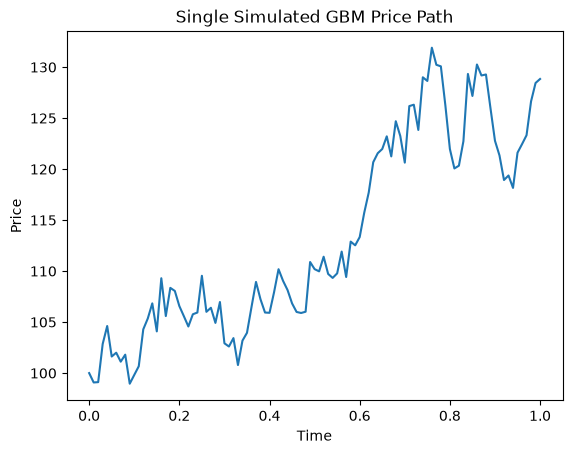

In [22]:
P0 = 100
mu = 0.4
sigma = 0.20
T = 1
n = 100

t_array = np.linspace(0, T, n + 1)
delta_t = T / n

rng = np.random.default_rng(4)

brownian_path = [0]
price_path = [P0]

for i in range(1, n + 1):

    increment = rng.normal(0, np.sqrt(delta_t))
    brownian_path.append(brownian_path[-1] + increment)

    price = P0 * np.exp((mu - 0.5 * sigma ** 2) * t_array[i] + sigma * brownian_path[-1])
    price_path.append(price)

plt.plot(t_array, price_path)
plt.xlabel("Time")
plt.ylabel("Price")
plt.title("Single Simulated GBM Price Path")
plt.show()


### Monte Carlo GBM Simulation

Monte Carlo simulation generates independent GBM paths using Gaussian Brownian increments. Each path follows the same drift and volatility parameters but differs through its random increments.

We first implement the simulation using nested Python loops before introducing NumPy vectorisation to improve computational efficiency.

In [23]:
P0 = 100
mu = 0.08
sigma = 0.20

M = 10000
T = 1
n = 100

t_array = np.linspace(0, T, n+1)
delta_t = T/n

rng = np.random.default_rng(4)

**Baseline: Nested Python Loops**

In [24]:
for _ in range(M):
    
    brownian_path = [0]
    price_path = [P0]

    for i in range(1, n + 1):
        increment = rng.normal(0, np.sqrt(delta_t))
        brownian_path.append(brownian_path[-1] + increment)

        price = P0 * np.exp((mu - 0.5 * sigma ** 2) * t_array[i] + sigma * brownian_path[-1])
        price_path.append(price)

**Fully Vectorised Simulation**

The nested Python loops are replaced with NumPy array operations. Brownian increments are generated for all paths simultaneously, with cumulative sums along the time axis.

The resulting array contains $M$ independent simulated paths, each with $n+1$ observation points.


In [25]:
M = 1000000

In [26]:
randoms = np.random.normal(0, np.sqrt(delta_t), size=(M, n))
zeros = np.array([[0]] * M)

brownian_increments = np.concatenate((zeros, randoms), axis = 1)
brownian = np.cumsum(brownian_increments, axis = 1)

diffusion = np.multiply(sigma, brownian)
drift = np.multiply(t_array, (mu - 0.5 * (sigma**2)))

price_factor = np.exp(drift + diffusion)
prices = np.multiply(P0, price_factor)

transposed_prices = prices.T

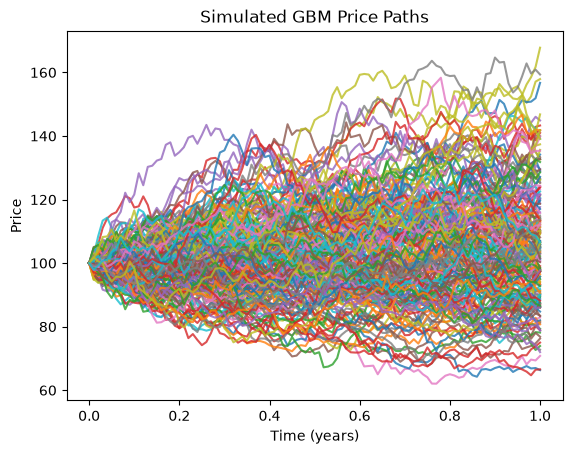

In [27]:
plt.plot(t_array, prices[:200].T, alpha = 0.8)
plt.xlabel("Time (years)")
plt.ylabel("Price")
plt.title("Simulated GBM Price Paths")
plt.show()


| Implementation | Runtime (ms) |
|---|---:|
| Nested Python loops | 1111 |
| Fully vectorised | 30.9 |

Vectorising the simulation reduced runtime from approximately 1.11 s to 30.9 ms for 10,000 paths, a speedup of roughly 36×


### Simulation Validation

Under geometric Brownian motion, terminal prices are lognormally distributed, with theoretical moments

$$
\mathbb{E}[P_T]=P_0e^{\mu T},
$$

$$
\operatorname{Var}(P_T)=P_0^2e^{2\mu T}(e^{\sigma^2T}-1).
$$

The simulated terminal-price distribution and sample moments are compared against these theoretical properties to assess the accuracy of the simulation.


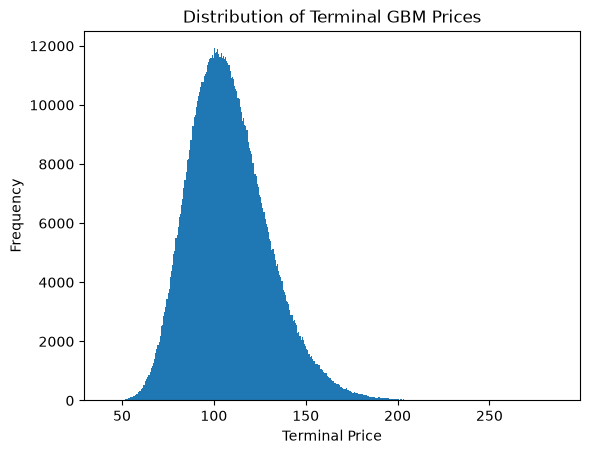

In [33]:
terminal_prices = prices[:, -1]

plt.hist(terminal_prices, bins = 400)
plt.xlabel("Terminal Price")
plt.ylabel("Frequency")
plt.title("Distribution of Terminal GBM Prices")
plt.show()

In [29]:
simulated_mean = np.mean(terminal_prices)
simulated_variance = np.var(terminal_prices)

theoretical_mean = P0 * np.exp(mu * T)
theoretical_variance = P0**2 * np.exp(2 * mu * T) * (np.exp(sigma**2 * T) - 1)

print("Terminal Prices")
print(f"Simulated mean:       {simulated_mean:.4f}")
print(f"Theoretical mean:     {theoretical_mean:.4f}")
print(f"Simulated variance:   {simulated_variance:.4f}")
print(f"Theoretical variance: {theoretical_variance:.4f}")

Terminal Prices
Simulated mean:       108.3051
Theoretical mean:     108.3287
Simulated variance:   479.2837
Theoretical variance: 478.9189



The simulated terminal prices exhibit the expected positively skewed, lognormal distribution. The sample mean and variance closely approximate their theoretical values, supporting the accuracy of the GBM simulation.



### Log-Return Validation

Under geometric Brownian motion, terminal log returns are normally distributed:

$$
\ln\left(\frac{P_T}{P_0}\right)\sim\mathcal{N}\left(\left(\mu-\frac12\sigma^2\right)T,\sigma^2T\right).
$$

The simulated distribution and sample moments are compared against these theoretical values.


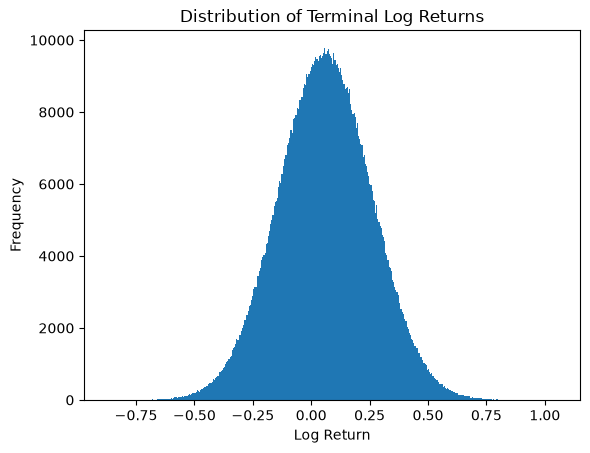

In [32]:
log_returns = np.log(terminal_prices / P0)

plt.hist(log_returns, bins = 400)
plt.xlabel("Log Return")
plt.ylabel("Frequency")
plt.title("Distribution of Terminal Log Returns")
plt.show()

In [31]:
simulated_log_mean = np.mean(log_returns)
simulated_log_var = np.var(log_returns)

theoretical_log_mean = (mu - 0.5 * sigma**2) * T
theoretical_log_var = sigma**2 * T

print("Terminal Log Returns")
print(f"Simulated mean:       {simulated_log_mean:.4f}")
print(f"Theoretical mean:     {theoretical_log_mean:.4f}")
print(f"Simulated variance:   {simulated_log_var:.4f}")
print(f"Theoretical variance: {theoretical_log_var:.4f}")

Terminal Log Returns
Simulated mean:       0.0598
Theoretical mean:     0.0600
Simulated variance:   0.0400
Theoretical variance: 0.0400



The simulated log returns exhibit an approximately normal distribution, with sample mean and variance close to their theoretical values. Together with the terminal-price validation, these results support the correctness of the GBM implementation.
